# **Otimização de Equipa de Basketball | Projeto MOTG | Mestrado Business Intelligence & Analytics**

### **Projeto desenvolvido por:**
- Beatriz Teixeira, nº2170307
- João Coelho, nº2200881
- João Vasques, nº2250055
- Rui Filipe Parada, nº2211025

---

### **Índice**
1. Imports
2. Data Upload
3. Overall Calculation
4. Gurobi Implementation

# **1. Imports**

In [ ]:
%pip install gurobipy

from google.colab import files
import io

import pandas as pd
from sklearn.preprocessing import MinMaxScaler
import gurobipy as gp
from gurobipy import GRB

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.8/14.8 MB 34.0 MB/s eta 0:00:00


# **2. Data Upload**

***Nota:***

O dataset que utilizamos neste projeto foi construído a partir de dados retirados do site: https://www.statmuse.com/nba/ask/boston-celtics-players-2025-season-stats

- ***'Bonus_per_Game'*** -> o bónus por titularidade no jogo representa 1% do salário base anual de cada jogador. Os valores salariais foram consultados em https://www.espn.com/nba/salaries/_/year/2025/page/10

- ***'Lidership'*** -> o grau de liderança de cada jogador foi projetado a partir da longevidade de cada um na NBA:
  - 1 a 2 anos (rookies): 1
  - 3 a 5 anos: 2
  - 6 a 8 anos: 3
  - 9 a 11 anos: 4
  - 12 anos ou mais: 5

In [ ]:
uploaded = files.upload()
df = pd.read_csv(io.BytesIO(uploaded['Celtic_Stats.csv']), sep=';')

Saving Celtic_Stats.csv to Celtic_Stats.csv


In [ ]:
df.head()

,Player_Name,Position,Minutes_per_Game,Points_per_Game,Assists_per_Game,Rebound_per_Game,Steals_per_Game,Blocks_per_Game,Bonus_per_Game,Lidership
0,Jrue Holiday,PG,30.6,11.1,3.9,4.3,1.1,0.4,300000,5
1,Al Horford,C,27.6,9.0,2.1,6.2,0.6,0.9,95000,5
2,Kristaps Porziņģis,C,28.8,19.5,2.1,6.8,0.7,1.5,292683,4
3,Jaylen Brown,SF,34.3,22.2,4.5,5.8,1.2,0.3,492058,4
4,Jayson Tatum,PF,36.4,26.8,6.0,8.7,1.1,0.5,348483,3


# **3. Overall Calculation**

Nesta secção, o nosso objetivo é calcular o overall de cada jogador, representado numa escala de 1 a 5. Para isso, combinamos as múltiplas métricas de desempenho presentes no dataset e normalizamo-las com recurso ao `MinMaxScaler`. Este scaler foi escolhido porque transforma todas as métricas numa escala uniforme entre 0 e 1. Isto é crucial para combinar as diferentes features, cujas unidades e amplitudes são distintas, já que garante que nenhuma domina o cálculo apenas por ter valores naturalmente maiores.

Contudo, não nos pareceu correto todos os atributos terem o mesmo impacto para o overall dos jogadores. Por exemplo, ***'Points_per_Game'*** e ***'Assists_per_Games'*** são métricas mais relevantes para posições ofensivas, enquanto que, ***'Steals_per_Game'*** e ***'Blocks_per_Game'*** devem ser mais valorizados para posições defensivas. Para contornar este problema e tornar o cálculo mais verídito e confiável, decidimos multiplicar cada atributo por um peso, mais ou menos elevado consoante a 'Position' em questão. De notar que os pesos, que somados igualam 1, não variam de posição para posição nas features ***'Minutes_per_Game'***, ***'Bonus_per_Game'*** e ***'Lidership'***, por estas serem igualmente importantes para todos os jogadores em campo.

Aplicamos esta ponderação para gerar um score agregado por jogador e, finalmente, categorizamos os 'scores' numa escala de 1 a 5, resultando no valor final de ***'Player_Overall'***. O resultado é uma tabela que resume, de forma objetiva e comparável, o desempenho global de cada atleta.

In [ ]:
### 3.1) SELEÇÃO DE FEATURES ###

features = ['Minutes_per_Game', 'Points_per_Game', 'Assists_per_Game', 'Rebound_per_Game', 'Steals_per_Game', 'Blocks_per_Game', 'Bonus_per_Game', 'Lidership']

In [ ]:
### 3.2) NORMALIZAÇÃO ###

scaler = MinMaxScaler()
df_scaled = df.copy()
df_scaled[features] = scaler.fit_transform(df[features])

In [ ]:
### 3.3) DEFINIÇÃO DOS WEIGHTS ###

weights = {
    "PG": {
        "Minutes_per_Game": 0.15,
        "Points_per_Game": 0.15,
        "Rebound_per_Game": 0.05,
        "Assists_per_Game": 0.30,
        "Steals_per_Game": 0.15,
        "Blocks_per_Game": 0.05,
        'Bonus_per_Game': 0.05,
        "Lidership": 0.10
    },
    "SG": {
        "Minutes_per_Game": 0.15,
        "Points_per_Game": 0.30,
        "Rebound_per_Game": 0.10,
        "Assists_per_Game": 0.15,
        "Steals_per_Game": 0.10,
        "Blocks_per_Game": 0.05,
        'Bonus_per_Game': 0.05,
        "Lidership": 0.10
    },
    "SF": {
        "Minutes_per_Game": 0.15,
        "Points_per_Game": 0.28,
        "Rebound_per_Game": 0.15,
        "Assists_per_Game": 0.07,
        "Steals_per_Game": 0.10,
        "Blocks_per_Game": 0.10,
        'Bonus_per_Game': 0.05,
        "Lidership": 0.10
    },
    "PF": {
        "Minutes_per_Game": 0.15,
        "Points_per_Game": 0.20,
        "Rebound_per_Game": 0.25,
        "Assists_per_Game": 0.05,
        "Steals_per_Game": 0.05,
        "Blocks_per_Game": 0.15,
        'Bonus_per_Game': 0.05,
        "Lidership": 0.10
    },
    "C": {
        "Minutes_per_Game": 0.15,
        "Points_per_Game": 0.15,
        "Rebound_per_Game": 0.24,
        "Assists_per_Game": 0.03,
        "Steals_per_Game": 0.04,
        "Blocks_per_Game": 0.24,
        'Bonus_per_Game': 0.05,
        "Lidership": 0.10
    }
}

In [ ]:
### 3.4) CÁLCULO DO SCORE ###

def compute_score(row):
    pos = row["Position"]
    w = weights[pos]
    return sum(row[f] * w[f] for f in w.keys())

In [ ]:
### 3.5) APLICAÇÃO DA FUNÇÃO compute_score ###

df_scaled["Score"] = df_scaled.apply(compute_score, axis=1)

In [ ]:
### 3.6) CATEGORIZAR NA ESCALA DE 1 A 5 ###

def score_to_overall(score):
    if score <= 0.20:
        return 1
    elif score <= 0.40:
        return 2
    elif score <= 0.60:
        return 3
    elif score <= 0.80:
        return 4
    else:
        return 5

df_scaled["Player_Overall"] = df_scaled["Score"].apply(score_to_overall)

In [ ]:
### 3.7) SCORE E OVERALL DE CADA JOGADOR ###

df_overall = df_scaled[["Player_Name", "Position", "Score", "Player_Overall"]].copy()

df_overall

,Player_Name,Position,Score,Player_Overall
0,Jrue Holiday,PG,0.676456,4
1,Al Horford,C,0.597783,3
2,Kristaps Porziņģis,C,0.778126,4
3,Jaylen Brown,SF,0.762353,4
4,Jayson Tatum,PF,0.830284,5
5,Derrick White,SG,0.660356,4
6,Luke Kornet,C,0.461353,3
7,Torrey Craig,SF,0.205922,2
8,Payton Pritchard,PG,0.525698,3
9,Xavier Tillman,C,0.086789,1


# **4. Gurobi Implementation**

O próximo passo é implementar a otimização da seleção da equipa com recurso ao Gurobi. Criamos uma instância do modelo, definimos variáveis binárias para cada jogador (se é ou não é titular) e configuramos a função objetivo para maximizar a performance global da equipa. Em seguida, aplicamos as restrições que definimos para o problema:
- a soma do 'Bonus_per_Game' da equipa não pode ser superior a 1M$;
- a equipa deve ser constituida por 5 jogadores;
- cada 'Position' não se pode repetir mais de 2 vezes;
- o plantel deve contar com pelo menos 1 Power Forward ("PF");
- um jogador só pode ser escolhido se o seu score for superior a 0.25.

Em seguida usamos `.optimize()` para calcular a solução ótima, registamos os resultados e analisamo-los.

In [ ]:
### 4.1) INSTÂNCIA DO MODELO DE OTIMIZAÇÃO ###

modelo = gp.Model()
x = modelo.addVars(df_overall['Player_Name'], name = "x",  vtype = GRB.BINARY)
modelo.update()

Restricted license - for non-production use only - expires 2027-11-29


In [ ]:
### 4.2) MAPEAMENTO E CONVERSÃO DE DADOS PARA USO NO SOLVER ###

player_overall_scores = df_overall.set_index('Player_Name')['Player_Overall']
bonus_per_game = df.set_index('Player_Name')['Bonus_per_Game']
posicoes = df_overall['Position'].unique()
jogadores_PF = df_overall[df_overall['Position'] == 'PF']['Player_Name']
low_score_players = df_scaled[df_scaled['Score'] <= 0.25]['Player_Name']

In [ ]:
### 4.3) FUNÇÃO OBJETIVO ###

objetivo = modelo.setObjective(gp.quicksum(player_overall_scores[player] * x[player] for player in df_overall['Player_Name']), GRB.MAXIMIZE)

In [ ]:
### 4.4) RESTRIÇÕES ###

modelo.addConstr(gp.quicksum(bonus_per_game[player_name] * x[player_name] for player_name in df_overall['Player_Name']) <= 1_000_000, name="Budget Max")

modelo.addConstr(gp.quicksum(x[player] for player in df_overall['Player_Name']) == 5, name="Team Size")

for pos in posicoes:
    jogadores_pos = df_overall[df_overall['Position'] == pos]['Player_Name']
    modelo.addConstr(gp.quicksum(x[player_name] for player_name in jogadores_pos) <= 2, name=f"Max_2_{pos}")

modelo.addConstr(gp.quicksum(x[player_name] for player_name in jogadores_PF) >= 1, name="Min_1_PF")

for player_name in low_score_players:
    modelo.addConstr(x[player_name] == 0, name=f"MinScore_{player_name}")



modelo.update()

In [ ]:
### 4.5) CÁLCULO DA SOLUÇÃO ÓTIMA ###

modelo.optimize()

Gurobi Optimizer version 13.0.0 build v13.0.0rc1 (linux64 - "Ubuntu 22.04.5 LTS")

CPU model: Intel(R) Xeon(R) CPU @ 2.20GHz, instruction set [SSE2|AVX|AVX2]
Thread count: 1 physical cores, 2 logical processors, using up to 2 threads

Optimize a model with 16 rows, 18 columns and 67 nonzeros (Max)
Model fingerprint: 0xc9527e05
Model has 18 linear objective coefficients
Variable types: 0 continuous, 18 integer (18 binary)
Coefficient statistics:
  Matrix range     [1e+00, 5e+05]
  Objective range  [1e+00, 5e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 1e+06]
Found heuristic solution: objective 15.0000000
Presolve removed 12 rows and 8 columns
Presolve time: 0.00s
Presolved: 4 rows, 10 columns, 26 nonzeros
Variable types: 0 continuous, 10 integer (10 binary)

Root relaxation: objective 1.927306e+01, 3 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Obj  Depth IntInf | Incumbent    Be

In [ ]:
### 4.6) RESULTADO DA OTIMIZAÇÃO ###

jogadores_escolhidos = pd.Series(modelo.getAttr('x', x), name = 'Jogadores escolhidos')
print(jogadores_escolhidos)

Jrue Holiday          0.0
Al Horford           -0.0
Kristaps Porziņģis    1.0
Jaylen Brown         -0.0
Jayson Tatum          1.0
Derrick White         1.0
Luke Kornet           1.0
Torrey Craig         -0.0
Payton Pritchard      1.0
Xavier Tillman       -0.0
Neemias Queta        -0.0
Jaden Springer       -0.0
Sam Hauser           -0.0
JD Davison           -0.0
Jordan Walsh         -0.0
Miles Norris         -0.0
Drew Peterson        -0.0
Baylor Scheierman    -0.0
Name: Jogadores escolhidos, dtype: float64


In [ ]:
### 4.7) JOGADORES SELECIONADOS ###

solucao = df_overall.set_index('Player_Name').join(jogadores_escolhidos.rename('Is_Selected'))
solucao = solucao[solucao['Is_Selected'] == 1].reset_index()
solucao = solucao[['Player_Name', 'Position', 'Player_Overall', 'Score']]
solucao

,Player_Name,Position,Player_Overall,Score
0,Kristaps Porziņģis,C,4,0.778126
1,Jayson Tatum,PF,5,0.830284
2,Derrick White,SG,4,0.660356
3,Luke Kornet,C,3,0.461353
4,Payton Pritchard,PG,3,0.525698


In [ ]:
### 4.8) RESPOSTA FINAL DO PROBLEMA ###

print(f"Numa escala de 0 a 25, o overall somado da equipa inicial é de {int(modelo.objVal)}, o que corresponde a uma performance de {modelo.objVal / 5}.")

jogadores_selecionados = [p for p in df_overall['Player_Name'] if x[p].X == 1]

print(f"\nOs jogadores escolhidos para a equipa são: {', '.join(jogadores_selecionados)}.")

Numa escala de 0 a 25, o overall somado da equipa inicial é de 19, o que corresponde a uma performance de 3.8.

Os jogadores escolhidos para a equipa são: Kristaps Porziņģis, Jayson Tatum, Derrick White, Luke Kornet, Payton Pritchard.


**Interpretação dos resultados**

A solução apresentada pelo modelo corresponde à seleção de 5 jogadores, dos 18 disponíveis, que maximizam a performance global da equipa, medida através da soma do ***'Player_Overall'***, respeitando todas as restrições que impusemos. Em particular, o modelo garante o cumprimento do limite máximo de budget para bónus por jogo (1 milhão de dólares), a diversidade posicional (no máximo dois jogadores por posição), a presença obrigatória de pelo menos um jogador da posição PF e a exclusão de jogadores com ***'Score'*** inferior a 0.25.

Os jogadores selecionados refletem um compromisso entre qualidade individual e viabilidade económica, evidenciando que o modelo não escolhe apenas os atletas com melhor performance isolada, mas sim aqueles que, em conjunto, permitem maximizar o desempenho total da equipa dentro dos limites estabelecidos.

A restrição do budget impede a seleção simultânea de jogadores com bónus elevados, mesmo que apresentem um ***'Score'*** superior. Adicionalmente, a restrição de diversidade posicional evita soluções irrealistas, como a seleção de jogadores exclusivamente da mesma posição, aproximando o resultado de um cinco inicial funcional em contexto real de jogo. A obrigatoriedade de um Power Forward segue a mesma intenção de obter uma solução realista. A imposição de um ***'Score'*** mínimo assegura ainda um nível base de qualidade, já que ignora jogadores com contributo estatisticamente inferior.

O cinco inicial otimizado para a equipa dos Celtics Boston é, então, composto por ***Kristaps Porziņģis, Jayson Tatum, Derrick White, Luke Kornet, Payton Pritchard***, com uma performance de ***3.8*** (numa escala de 0 a 5). Analisando face às restrições, verificamos que:
- foram escolhidos 5 jogadores
- o bónus total a ser entregue é de 927219.00 $
- nenhuma posição se repete mais de duas vezes
- a equipa conta com 1 Power Forward (Jason Tatum)
- nenhum jogador escolhido tem um score inferior a 0.25

De forma geral, os resultados demonstram que o modelo é capaz de traduzir critérios desportivos e financeiros num problema de otimização bem definido, produzindo uma solução coerente, interpretável e alinhada com as restrições impostas. De apontar que este tipo de abordagem pode ser facilmente estendido com novas restrições ou métricas, permitindo analisar diferentes cenários de construção da equipa.

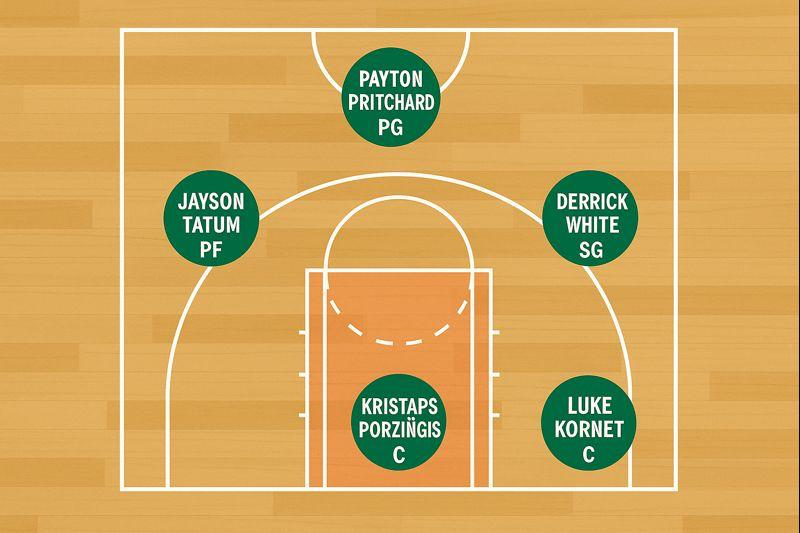